# EDA — HSE RecSys Challenge 2026

Разведочный анализ данных: структура данных и гипотезы, которые потом проверялись моделями.
Итоги проверок и выбор финальной модели описаны в `REPORT.md`, финальное решение — в `solution.ipynb`.

In [1]:
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import normalize

%config InlineBackend.figure_format = 'retina'
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (10, 4)
SEED = 42

DATA = 'data'
events = pd.read_csv(f'{DATA}/events.csv')
users = pd.read_csv(f'{DATA}/user_features.csv').sort_values('user_id').reset_index(drop=True)
items = pd.read_csv(f'{DATA}/item_features.csv').sort_values('item_id').reset_index(drop=True)
sample = pd.read_csv(f'{DATA}/submission_sample.csv')
GENRES = [c for c in items.columns if c.startswith('genre_')]
N_USERS, N_ITEMS = len(users), len(items)

## 1. Общий обзор

In [2]:
print(f'events: {len(events):,} | users: {N_USERS} | items: {N_ITEMS}')
print(f'users в events: {events.user_id.nunique()}, items в events: {events.item_id.nunique()}')
print(f'разреженность матрицы: {1 - len(events) / (N_USERS * N_ITEMS):.2%}')
print(f'дубликатов (user, item): {events.duplicated(["user_id", "item_id"]).sum()}')
print(f'пользователей в сабмите: {sample.user_id.nunique()}, все есть в events: {sample.user_id.isin(events.user_id).all()}')
events.head()

events: 894,149 | users: 6040 | items: 3706
users в events: 6040, items в events: 3690
разреженность матрицы: 96.01%
дубликатов (user, item): 0
пользователей в сабмите: 6040, все есть в events: True


,user_id,item_id,rating,timestamp
0,0,1505,4,0
1,0,3669,3,1
2,0,584,4,2
3,0,3390,3,3
4,0,2885,4,4


**Наблюдения.** 6040 пользователей, 3706 фильмов, около 894 тыс. оценок. По размерам это MovieLens-1M
(1 000 209 оценок), то есть около 10% оценок скрыто. Холодного старта по пользователям нет.
Повторных пар «пользователь — фильм» нет, поэтому уже оценённые фильмы нужно исключать из рекомендаций.
16 фильмов не оценены ни разу.

## 2. Оценки

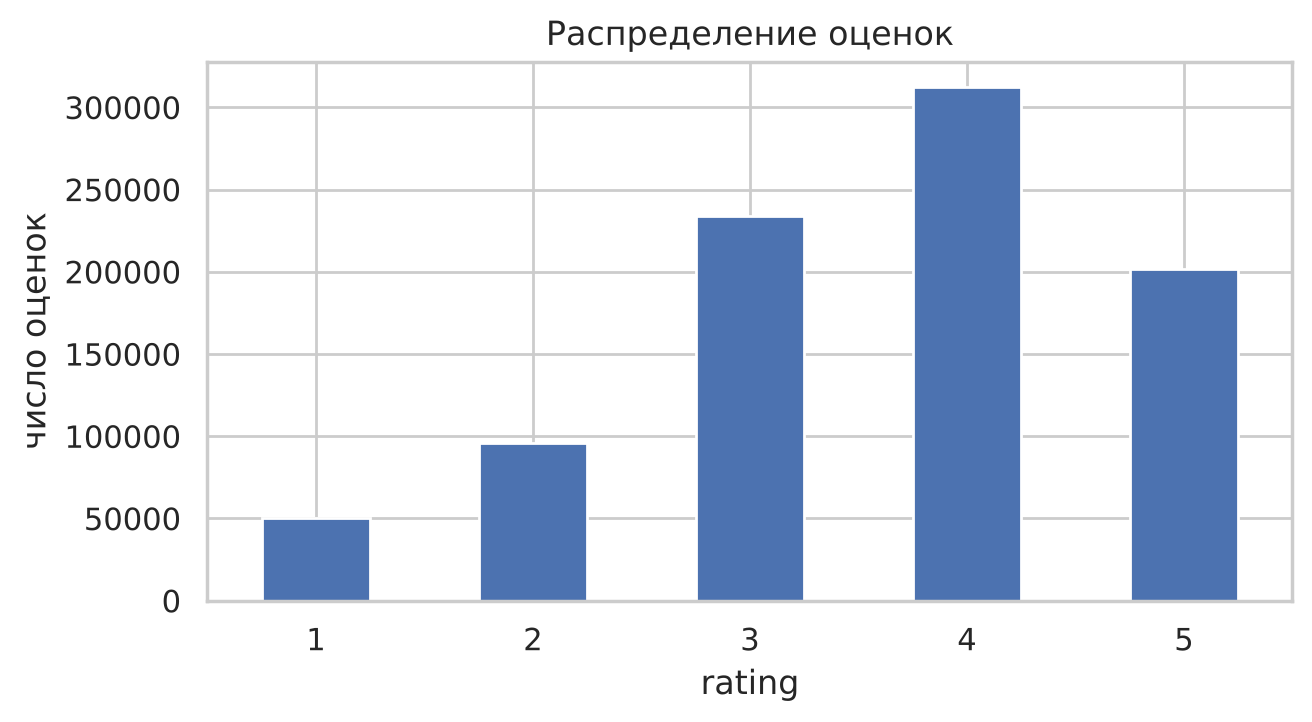

доля оценок ≥ 4: 57.5%


In [3]:
ax = events.rating.value_counts().sort_index().plot.bar(color='#4C72B0', figsize=(7, 3.5))
ax.set(title='Распределение оценок', xlabel='rating', ylabel='число оценок'); plt.xticks(rotation=0); plt.show()
print(f'доля оценок ≥ 4: {(events.rating >= 4).mean():.1%}')

Больше половины оценок — 4 и 5: люди оценивают то, что сами выбрали посмотреть.

**H1:** для recall важен сам факт оценки, а не её значение → бинарная матрица взаимодействий.

## 3. Активность пользователей и популярность фильмов

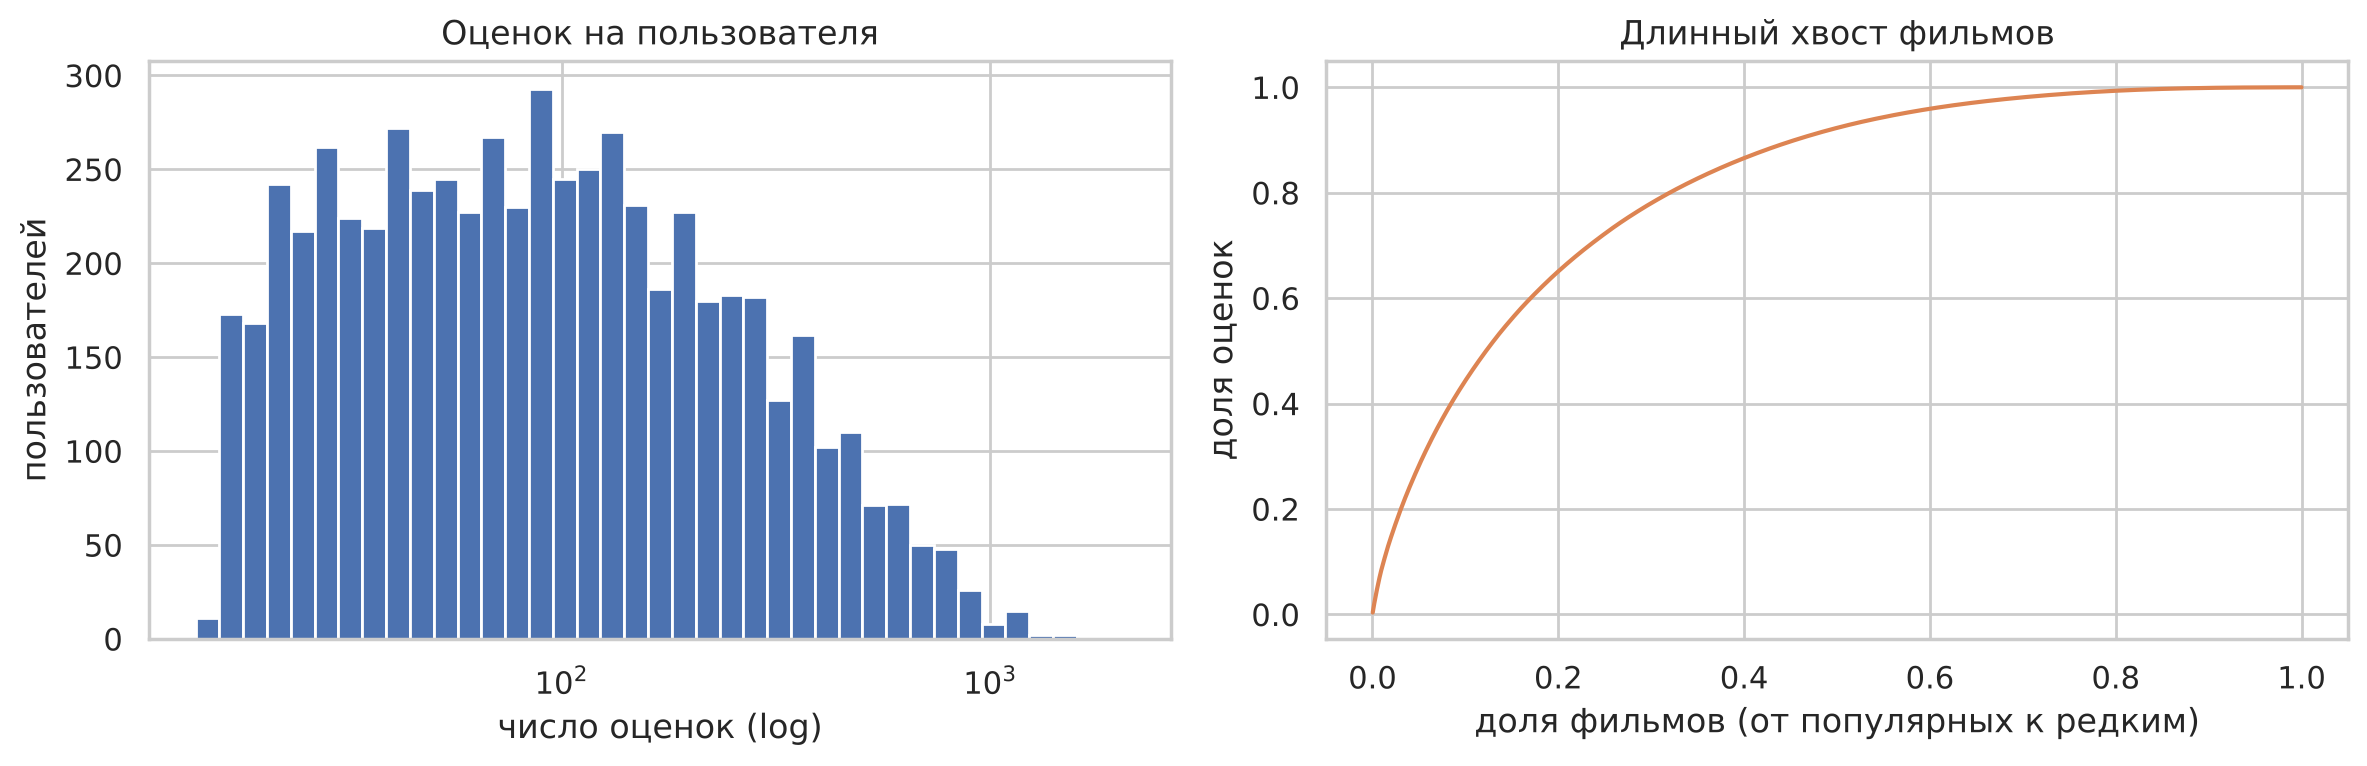

оценок на пользователя: min=14, медиана=84, max=2056
top-10% фильмов собирают 44% оценок


In [4]:
user_cnt = events.groupby('user_id').size()
item_cnt = events.groupby('item_id').size().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(user_cnt, bins=np.logspace(np.log10(user_cnt.min()), np.log10(user_cnt.max()), 40), color='#4C72B0')
axes[0].set(xscale='log', title='Оценок на пользователя', xlabel='число оценок (log)', ylabel='пользователей')
share = item_cnt.cumsum() / item_cnt.sum()
axes[1].plot(np.arange(1, len(share) + 1) / len(share), share.values, color='#DD8452')
axes[1].set(title='Длинный хвост фильмов', xlabel='доля фильмов (от популярных к редким)', ylabel='доля оценок')
plt.tight_layout(); plt.show()
print(f'оценок на пользователя: min={user_cnt.min()}, медиана={user_cnt.median():.0f}, max={user_cnt.max()}')
print(f'top-10% фильмов собирают {share.iloc[int(len(share) * 0.1)]:.0%} оценок')

История есть у всех (минимум 14 оценок), популярность устроена как длинный хвост.

**H2:** популярное — бейзлайн, коллаборативные модели (ItemKNN, iALS, EASE) должны его заметно обойти.

## 4. Пользователи и жанры

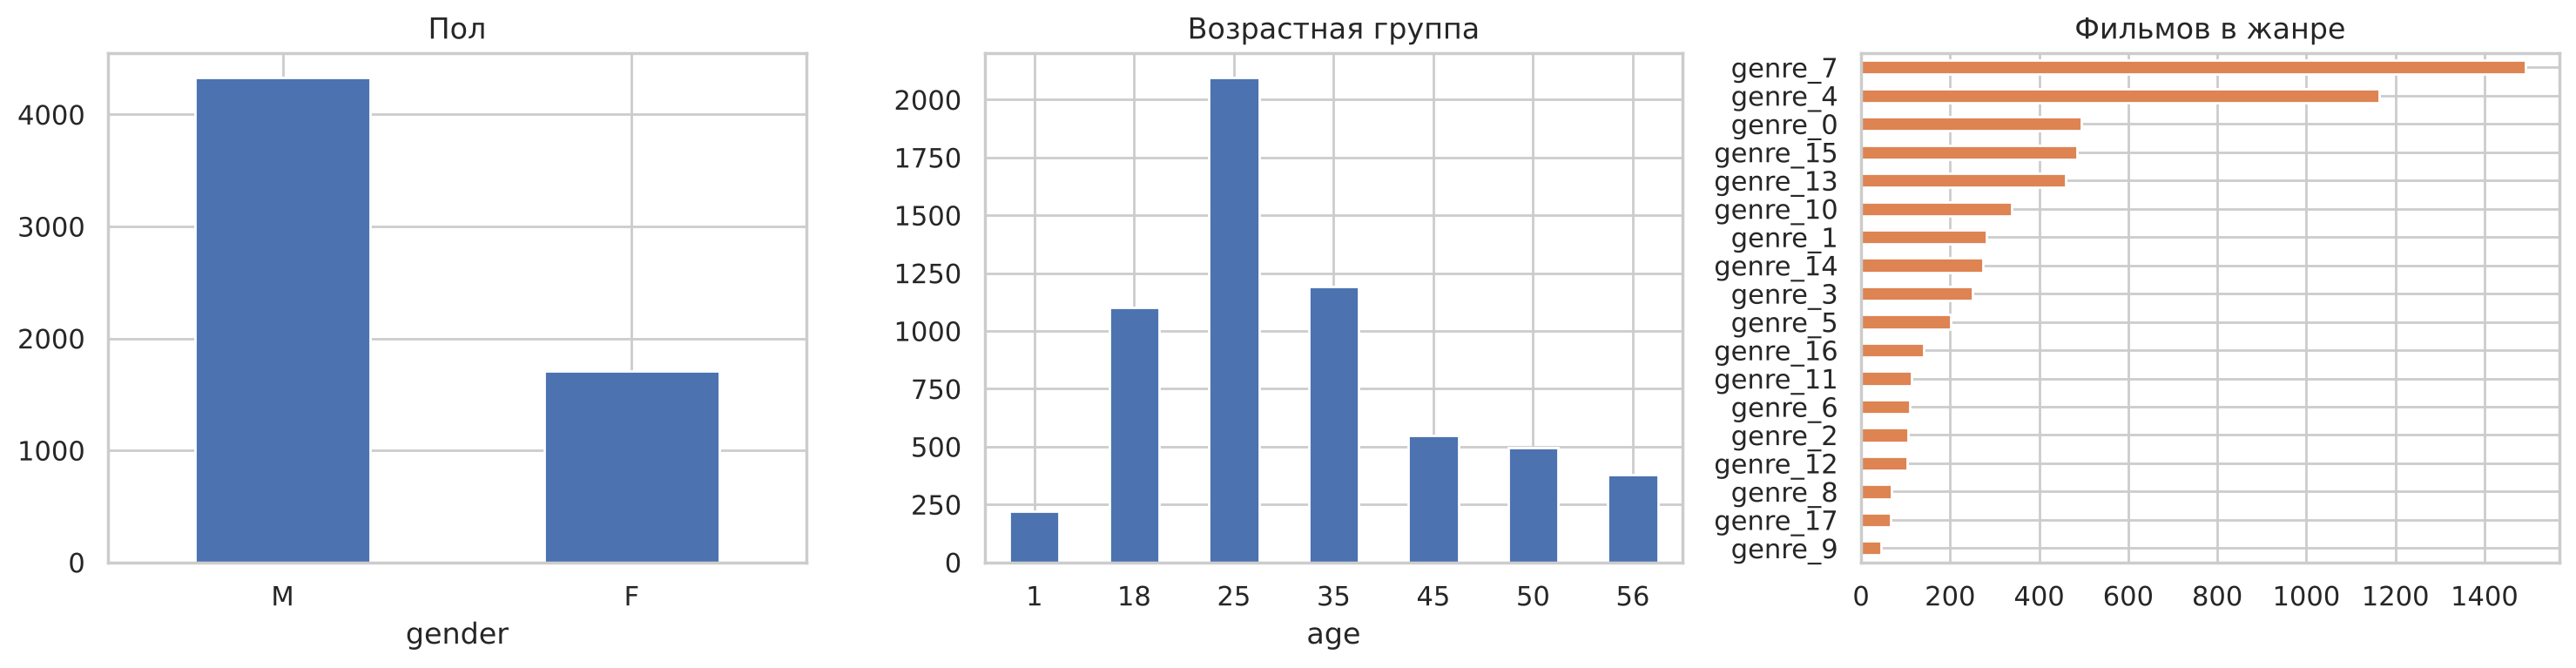

пересечение top-50 фильмов у M и F: 31 из 50
жанров на фильм в среднем: 1.67


In [5]:
df = users.merge(user_cnt.rename('n'), left_on='user_id', right_index=True)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
df.gender.value_counts().plot.bar(ax=axes[0], color='#4C72B0', title='Пол')
df.age.value_counts().sort_index().plot.bar(ax=axes[1], color='#4C72B0', title='Возрастная группа')
items[GENRES].sum().sort_values().plot.barh(ax=axes[2], color='#DD8452', title='Фильмов в жанре')
for a in axes[:2]: a.tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

ev_u = events.merge(users, on='user_id')
top = {g: set(ev_u[ev_u.gender == g].item_id.value_counts().index[:50]) for g in ['M', 'F']}
print(f'пересечение top-50 фильмов у M и F: {len(top["M"] & top["F"])} из 50')
print(f'жанров на фильм в среднем: {items[GENRES].sum(axis=1).mean():.2f}')

Вкусы демографических групп различаются лишь частично. Жанры анонимизированы и грубые
(18 жанров на 3706 фильмов, в среднем 1–2 жанра у фильма).

**H3:** демография и жанры — слабые сигналы по сравнению с историей оценок.

## 5. Что такое `timestamp`

In [6]:
g = events.groupby('user_id').timestamp.agg(['min', 'max', 'size', 'nunique'])
print(f'timestamp max = {events.timestamp.max()} — это не unix-время')
print(f'уникален внутри пользователя: {(g["nunique"] == g["size"]).mean():.0%}, начинается с 0: {(g["min"] == 0).mean():.0%}')
print(f'нумерация без пропусков (max == size-1): {(g["max"] == g["size"] - 1).mean():.1%}')

timestamp max = 2312 — это не unix-время
уникален внутри пользователя: 100%, начинается с 0: 91%
нумерация без пропусков (max == size-1): 1.7%


`timestamp` — порядковый номер оценки в истории пользователя, а не календарное время.

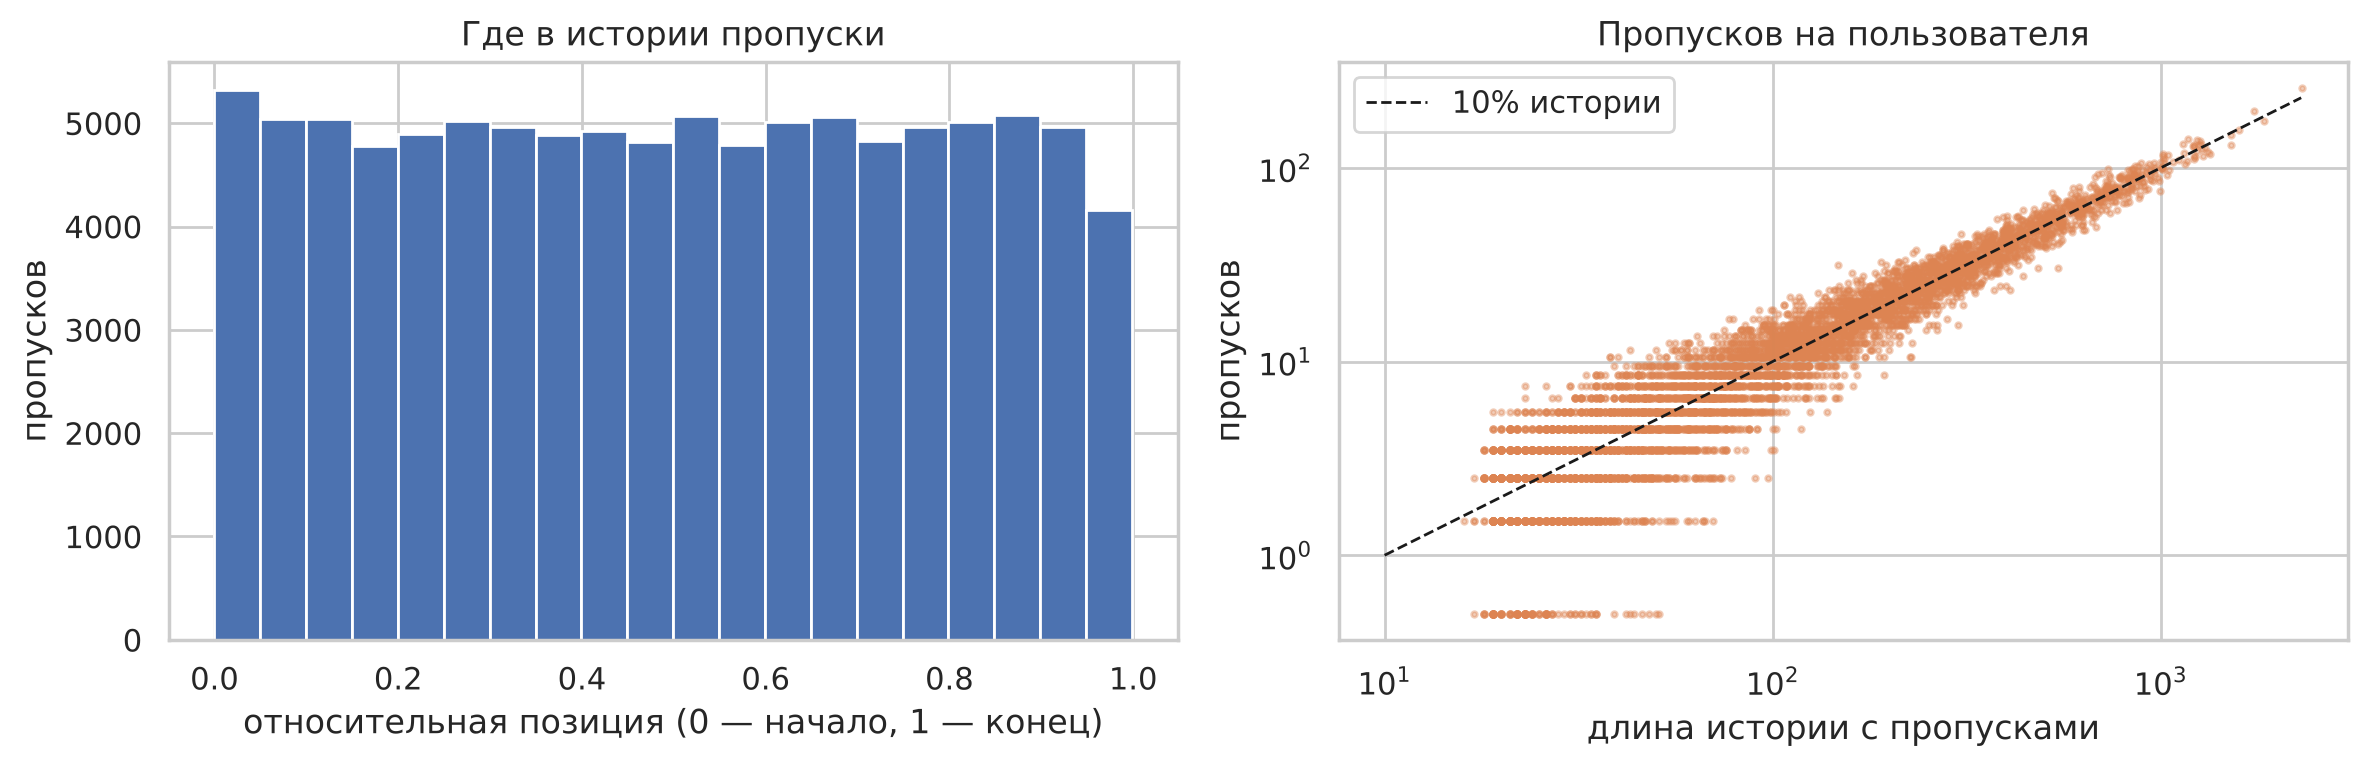

пропусков внутри историй: 98,628


In [7]:
gaps_rel, gaps_cnt = [], {}
for u, ts in events.groupby('user_id').timestamp:
    present = np.zeros(ts.max() + 1, bool); present[ts.values] = True
    missing = np.flatnonzero(~present)
    gaps_cnt[u] = len(missing); gaps_rel.extend(missing / len(present))
gaps_cnt = pd.Series(gaps_cnt)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(gaps_rel, bins=20, color='#4C72B0')
axes[0].set(title='Где в истории пропуски', xlabel='относительная позиция (0 — начало, 1 — конец)', ylabel='пропусков')
axes[1].scatter(user_cnt + gaps_cnt, gaps_cnt + 0.5, s=4, alpha=0.4, color='#DD8452')
axes[1].plot([10, 2300], [1, 230], 'k--', lw=1, label='10% истории')
axes[1].set(title='Пропусков на пользователя', xlabel='длина истории с пропусками', ylabel='пропусков',
            xscale='log', yscale='log')
axes[1].legend(); plt.tight_layout(); plt.show()
print(f'пропусков внутри историй: {gaps_cnt.sum():,}')

Пропуски равномерно распределены по истории, их около 10% её длины.

**Что это значит для валидации.** Для рекомендаций по умолчанию берут временной сплит (предсказываем
следующие оценки по прошлым). Равномерные пропуски наводят на альтернативу — случайный сплит
(скрываем случайные 10% оценок), если скрытые оценки разбросаны по всей истории. Выбор между схемами
делаем по согласию локальной метрики с лидербордом (`REPORT.md`, раздел 2): случайный сплит с лидербордом
**не согласовался** (валидация 0.217 → лидерборд 0.080), временной — согласовался (0.267 → 0.2447).

## 6. Несёт ли порядок оценок сигнал

Если тест — продолжение истории, то важно, похожи ли соседние по порядку оценки
и описывают ли последние оценки ближайший интерес пользователя.

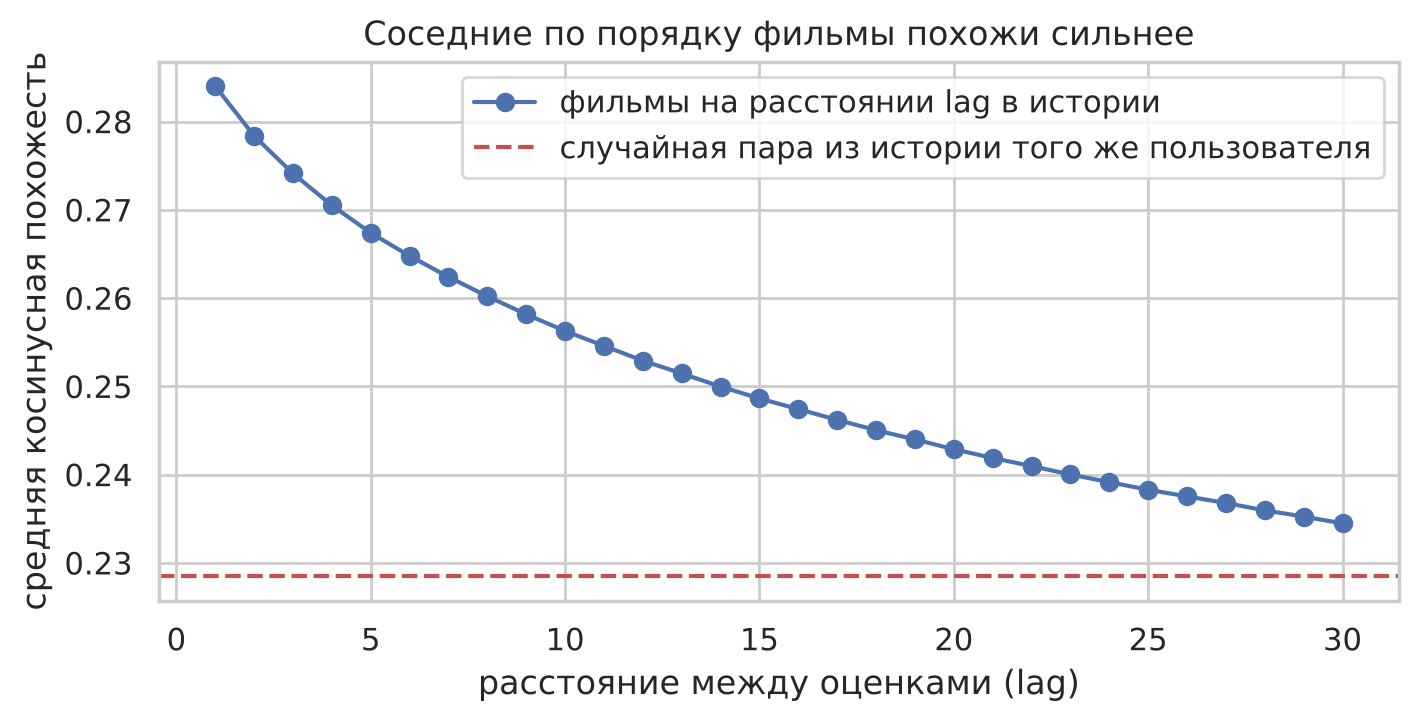

In [8]:
X = sp.csr_matrix((np.ones(len(events), np.float32), (events.user_id, events.item_id)), shape=(N_USERS, N_ITEMS))
Xn = normalize(X, axis=0); S = (Xn.T @ Xn).toarray(); np.fill_diagonal(S, 0)   # косинусная похожесть фильмов

e = events.sort_values(['user_id', 'timestamp'])
u_arr, i_arr = e.user_id.values, e.item_id.values
lags = list(range(1, 31))
lag_sim = []
for l in lags:
    m = u_arr[l:] == u_arr[:-l]
    lag_sim.append(S[i_arr[l:][m], i_arr[:-l][m]].mean())
rng = np.random.default_rng(SEED)
perm = e.groupby('user_id').item_id.transform(lambda s: rng.permutation(s.values)).values
same = u_arr[1:] == u_arr[:-1]
rand_sim = S[i_arr[1:][same], perm[:-1][same]].mean()

plt.figure(figsize=(8, 3.5))
plt.plot(lags, lag_sim, 'o-', color='#4C72B0', label='фильмы на расстоянии lag в истории')
plt.axhline(rand_sim, color='#C44E52', ls='--', label='случайная пара из истории того же пользователя')
plt.xlabel('расстояние между оценками (lag)'); plt.ylabel('средняя косинусная похожесть')
plt.title('Соседние по порядку фильмы похожи сильнее'); plt.legend(); plt.show()

Соседние оценки похожи сильнее случайных, и эффект затухает с расстоянием: пользователи оценивают
фильмы «сессиями». Значит, недавние оценки описывают текущий интерес лучше, чем вся история.

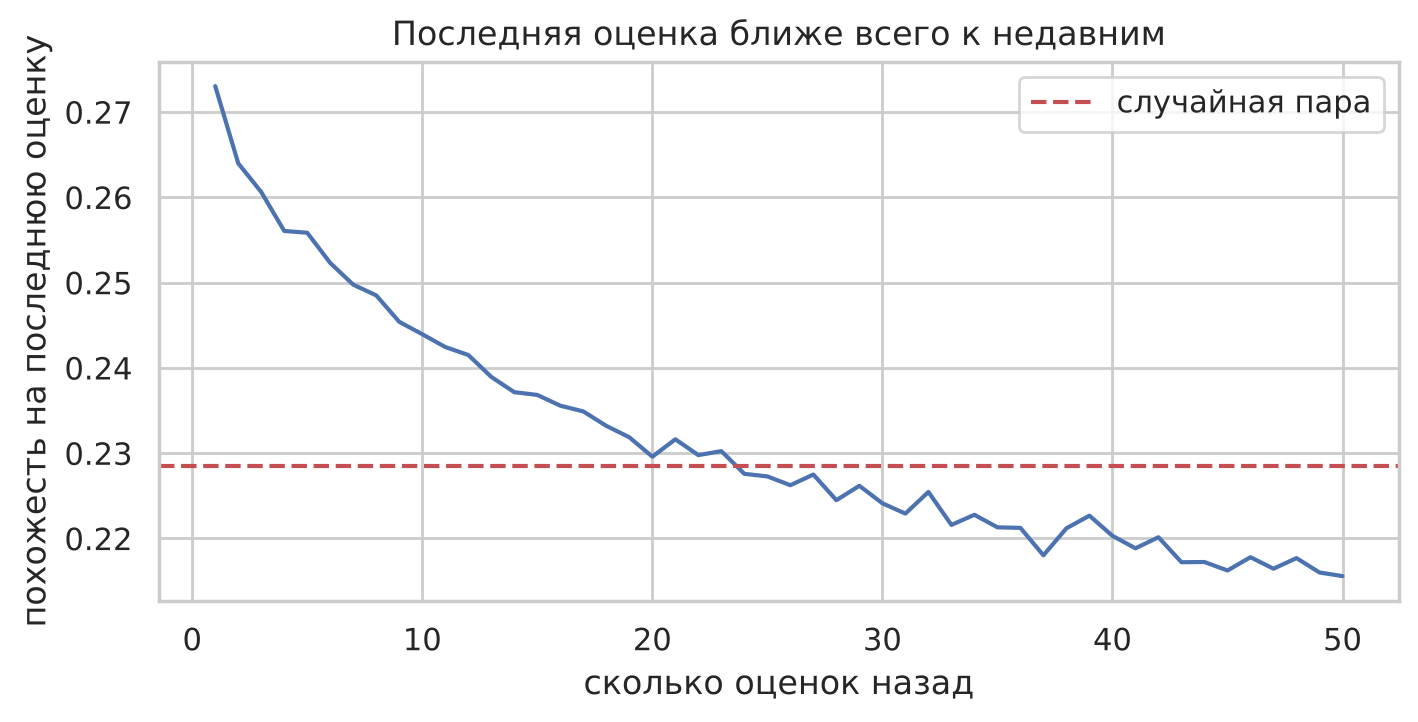

In [9]:
# Насколько последняя оценка пользователя похожа на оценки, сделанные за d шагов до неё
pos_from_end = e.groupby('user_id').cumcount(ascending=False).values
last_item = e.groupby('user_id').item_id.transform('last').values
dist = np.arange(1, 51)
sim_to_last = [S[last_item[pos_from_end == d], i_arr[pos_from_end == d]].mean() for d in dist]

plt.figure(figsize=(8, 3.5))
plt.plot(dist, sim_to_last, color='#4C72B0')
plt.axhline(rand_sim, color='#C44E52', ls='--', label='случайная пара')
plt.xlabel('сколько оценок назад'); plt.ylabel('похожесть на последнюю оценку')
plt.title('Последняя оценка ближе всего к недавним'); plt.legend(); plt.show()

In [10]:
# Дрейф вкуса: жанровый профиль первой и последней четверти истории
G = items[GENRES].values.astype(np.float32)
q = e.groupby('user_id').cumcount() / e.groupby('user_id').user_id.transform('size')
def profile(mask):
    sub = e[mask.values]
    return normalize(np.asarray(sp.csr_matrix((np.ones(len(sub)), (sub.user_id, sub.item_id)),
                                              shape=(N_USERS, N_ITEMS)) @ G))
first, last, mid = profile(q < 0.25), profile(q >= 0.75), profile((q >= 0.25) & (q < 0.75))
print(f'косинус жанровых профилей: середина ↔ последняя четверть = {(mid * last).sum(1).mean():.3f}, '
      f'первая ↔ последняя четверть = {(first * last).sum(1).mean():.3f}')

косинус жанровых профилей: середина ↔ последняя четверть = 0.766, первая ↔ последняя четверть = 0.687


Жанровый профиль меняется по ходу истории: чем дальше части истории друг от друга, тем меньше они похожи.

**Гипотеза:** главный сигнал — **последние оценки и их порядок**, общий вкус (EASE по всей истории)
полезен как дополнение. Направление тоже может быть важно: модель «что идёт *после*» должна быть лучше
модели «что встречается *рядом*».

## 7. Итоги EDA

| Наблюдение | Что из него следует | Где проверяется |
|---|---|---|
| 57% оценок — 4 и 5 | бинарная матрица (оценил / не оценил) не хуже взвешенной по рейтингу | EASE с разными весами |
| история есть у всех, длинный хвост популярности | коллаборативные модели должны сильно обойти популярное | Popular → ItemKNN → iALS → EASE |
| демография и жанры слабо разделяют вкусы | это слабые признаки | популярное по группам, жанровый профиль, ранкер |
| пропуски в нумерации равномерны по истории | две кандидатные схемы валидации: случайный и временной сплит | согласие с лидербордом |
| соседние оценки похожи, вкус дрейфует | важны последние оценки и их порядок | локальная EASE, directed ridge |

Результаты всех проверок и выбор финальной модели — в `REPORT.md`.